In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"D:\project\customer-behavior-analysis\data\raw\shopping_trends_cleaned.csv")
df.shape

(3900, 20)

In [23]:
df["purchase_amount_usd"].sum()

np.int64(233081)

In [24]:
df["purchase_amount_usd"].mean()

np.float64(59.76435897435898)

In [25]:
(df.groupby("age_group")["purchase_amount_usd"]
   .agg(["count", "mean", "sum"]).round(2))

,count,mean,sum
age_group,,,
18-25,545,60.74,33106
26-35,706,59.95,42324
36-45,848,59.32,50307
46-55,724,60.52,43814
56-65,733,59.18,43382
66+,344,58.57,20148


In [26]:
df.groupby("gender")["purchase_amount_usd"].agg(["count", "mean", "sum"]).round(2)

,count,mean,sum
gender,,,
Female,1248,60.25,75191
Male,2652,59.54,157890


In [27]:
(df.groupby("location")["purchase_amount_usd"].sum()
   .sort_values(ascending=False).head(5))

location
Montana       5784
Illinois      5617
California    5605
Idaho         5587
Nevada        5514
Name: purchase_amount_usd, dtype: int64

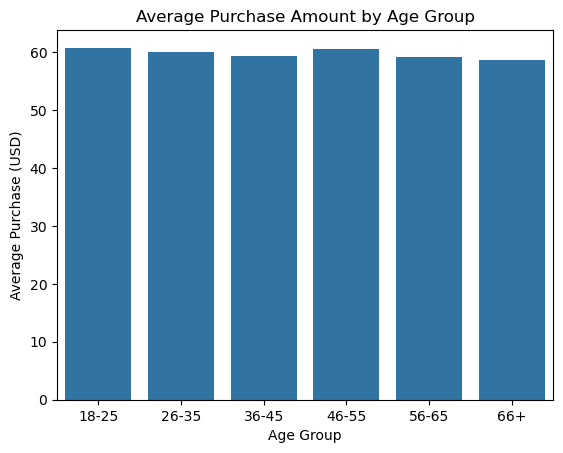

In [28]:
order = ["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
sns.barplot(data=df, x="age_group", y="purchase_amount_usd", order=order, errorbar=None)
plt.title("Average Purchase Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Purchase (USD)")
plt.show()

In [29]:
(df.groupby("category")["purchase_amount_usd"]
   .agg(["count", "sum", "mean"]).round(2)
   .sort_values("sum", ascending=False))

,count,sum,mean
category,,,
Clothing,1737,104264,60.03
Accessories,1240,74200,59.84
Footwear,599,36093,60.26
Outerwear,324,18524,57.17


In [30]:
share = df.groupby("category")["purchase_amount_usd"].sum()
(share / share.sum() * 100).round(1).sort_values(ascending=False)

category
Clothing       44.7
Accessories    31.8
Footwear       15.5
Outerwear       7.9
Name: purchase_amount_usd, dtype: float64

In [31]:
(df.groupby("season")["purchase_amount_usd"]
   .agg(["count", "sum", "mean"]).round(2)
   .sort_values("sum", ascending=False))

,count,sum,mean
season,,,
Spring,1067,62735,58.80
Fall,951,58453,61.46
Winter,953,57708,60.55
Summer,929,54185,58.33


In [32]:
pd.crosstab(df["season"], df["category"])

category,Accessories,Clothing,Footwear,Outerwear
season,,,,
Fall,318,414,133,86
Spring,320,484,175,88
Summer,306,396,154,73
Winter,296,443,137,77


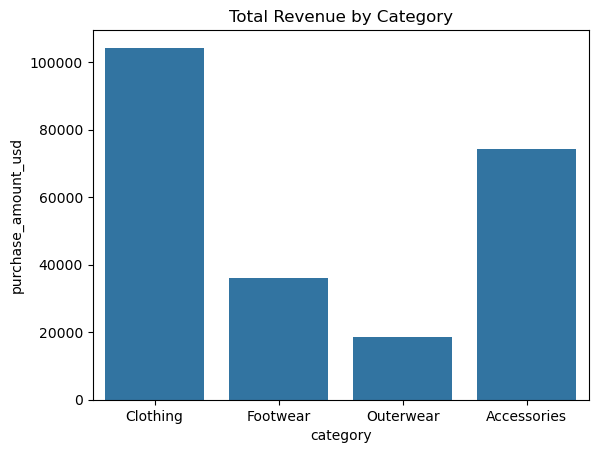

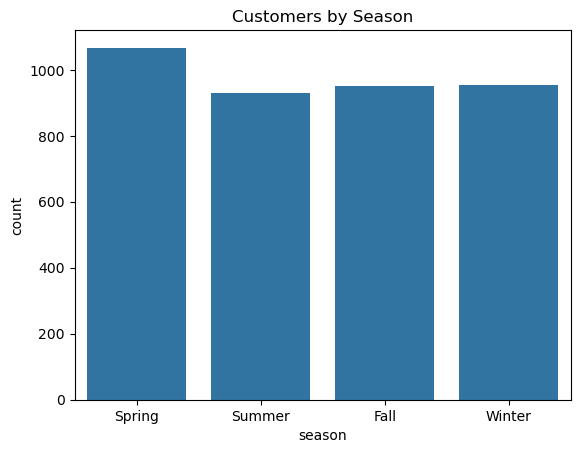

In [33]:
sns.barplot(data=df, x="category", y="purchase_amount_usd", estimator="sum", errorbar=None)
plt.title("Total Revenue by Category")
plt.show()

sns.countplot(data=df, x="season", order=["Spring", "Summer", "Fall", "Winter"])
plt.title("Customers by Season")
plt.show()

In [34]:
(df.groupby("subscription_status")["purchase_amount_usd"]
   .agg(["count", "mean", "sum"]).round(2))

,count,mean,sum
subscription_status,,,
No,2847,59.87,170436
Yes,1053,59.49,62645


In [35]:
(df.groupby("discount_applied")["purchase_amount_usd"]
   .agg(["count", "mean", "sum"]).round(2))

,count,mean,sum
discount_applied,,,
No,2223,60.13,133670
Yes,1677,59.28,99411


In [36]:
df["payment_method"].value_counts()
df.groupby("payment_method")["purchase_amount_usd"].mean().round(2)

payment_method
Bank Transfer    58.74
Cash             59.93
Credit Card      61.16
Debit Card       58.64
PayPal           58.70
Venmo            61.24
Name: purchase_amount_usd, dtype: float64

In [37]:
df["frequency_of_purchases"].value_counts()

frequency_of_purchases
Quarterly    1147
Bi-Weekly    1089
Annually      572
Monthly       553
Weekly        539
Name: count, dtype: int64

In [38]:
(df["payment_method"] == df["preferred_payment_method"]).mean().round(3)

np.float64(0.158)

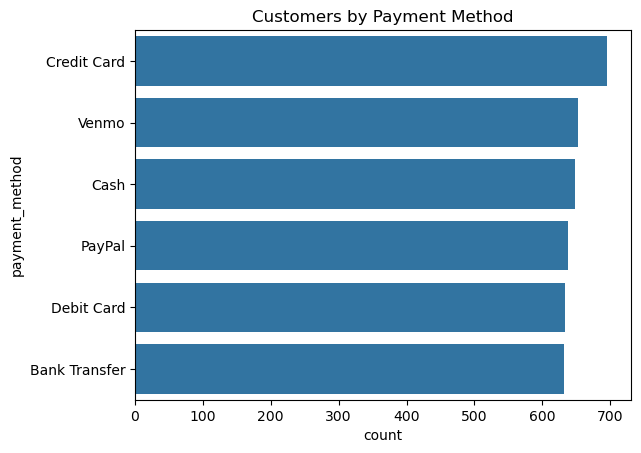

In [39]:
sns.countplot(data=df, y="payment_method", order=df["payment_method"].value_counts().index)
plt.title("Customers by Payment Method")
plt.show()